# Phase 7 — Explainable AI with SHAP

This notebook explores how SHAP explains the saved FraudShield XGBoost model. Run it from the project root after Phase 5 and Phase 6 have produced `models/xgboost_best.joblib` and `models/decision_policy.json`.

**Important:** these explanations describe how features contribute to the model's output relative to a selected background dataset. They do not prove causation, validate probability calibration, or reveal the real-world meaning of anonymized PCA components `V1`–`V28`.

## 1. SHAP fundamentals

For a single row, SHAP gives an additive decomposition:

`model output ≈ base value + sum(feature SHAP values)`

- The **base value** is the model output averaged over the explainer's background/reference data.
- A positive SHAP value pushes the model score upward relative to that baseline.
- A negative SHAP value pushes the model score downward.
- The absolute size is a contribution on the model output scale. Here we explain the XGBoost `predict_proba` output; that output is still an **uncalibrated model score**, not a verified real-world fraud probability.

The current background contains a reproducible sample of 100 rows from the model-fit period.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

REPORTS = Path("reports/explainability")
importance = pd.read_csv(REPORTS / "global_shap_importance.csv")
summary = json.loads((REPORTS / "shap_summary.json").read_text(encoding="utf-8"))
print("Background rows:", summary["background_rows"])
print("Explanation sample rows:", summary["test_rows_in_explanation_sample"])
print("Fraud cases in explanation sample:", summary["test_fraud_rows_in_explanation_sample"])
print("Legitimate cases in explanation sample:", summary["test_legitimate_rows_in_explanation_sample"])
print("Max SHAP additivity error:", summary["max_absolute_shap_additivity_error"])
display(importance.head(10))

Background rows: 100
Explanation sample rows: 376
Fraud cases in explanation sample: 75
Legitimate cases in explanation sample: 301
Max SHAP additivity error: 1.1016657741613756e-07


,feature,mean_abs_shap_value,mean_shap_value,fraction_positive_contribution,fraction_negative_contribution
0,V14,0.064349,0.060048,0.449468,0.550532
1,V4,0.038811,0.030694,0.303191,0.696809
2,V12,0.030579,0.025246,0.375000,0.625000
3,V10,0.019510,0.018405,0.199468,0.800532
4,V17,0.010911,0.009643,0.281915,0.718085
5,V11,0.003551,0.002883,0.614362,0.385638
6,V3,0.003223,0.003030,0.941489,0.058511
7,V21,0.002872,0.002399,0.300532,0.699468
8,V16,0.002858,0.002503,0.289894,0.710106
9,V8,0.002466,-0.000779,0.587766,0.412234


## 2. Global explanations

Global SHAP importance aggregates feature contributions across a sample of transactions. We include **all 75 fraud cases in the historical test partition and a deterministic sample of 301 legitimate cases** so the rare positive class is visible. This sample is intentionally case-enriched; mean absolute SHAP values from it are **not** population-prevalence-weighted estimates.

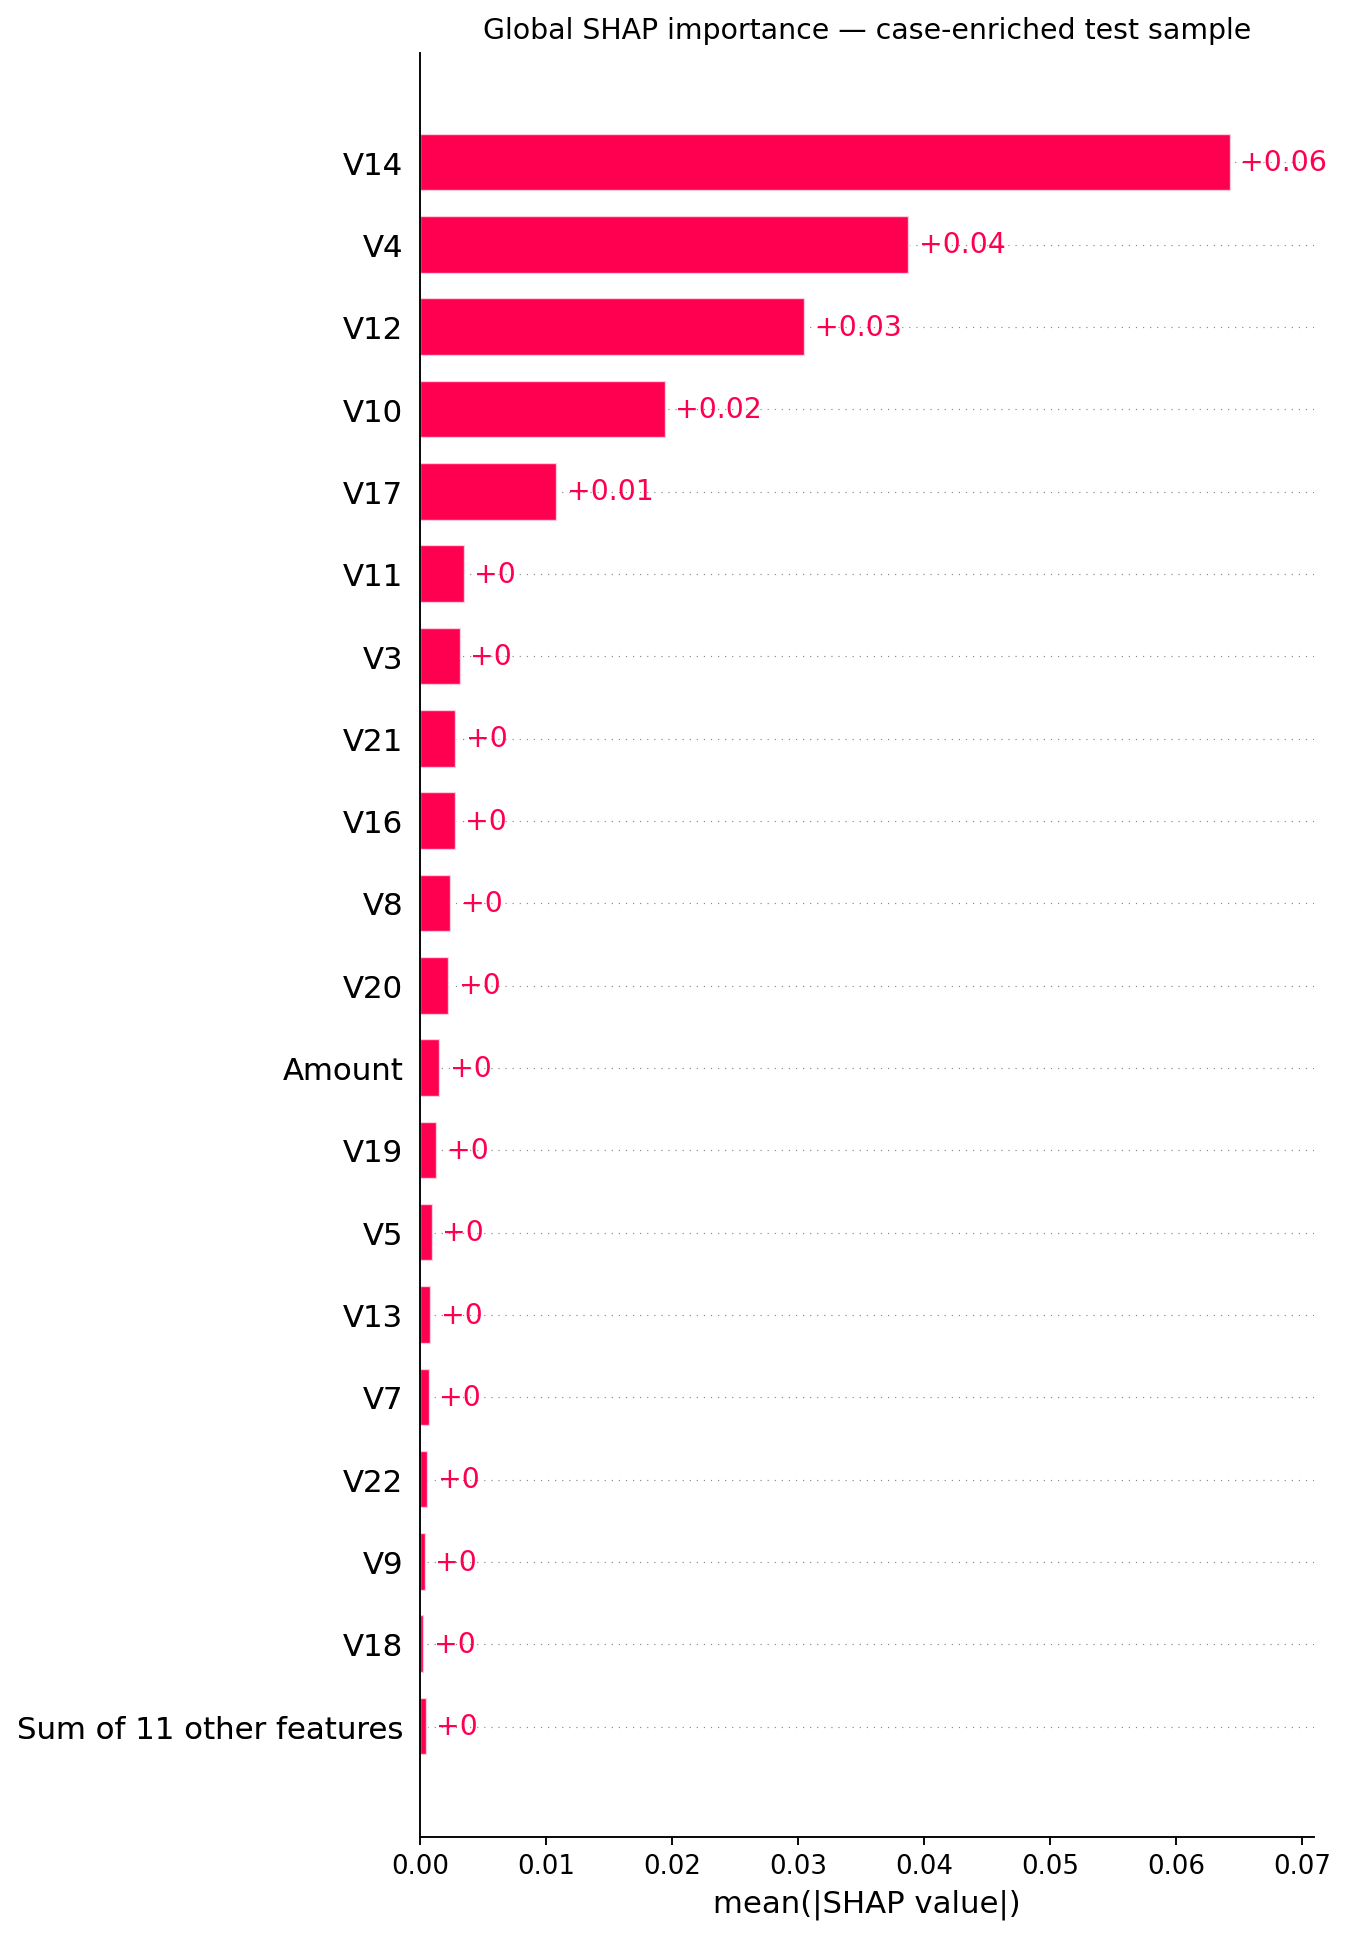

In [2]:
display(Image(filename=str(REPORTS / "global_shap_bar.png")))

### SHAP beeswarm

The beeswarm shows the distribution and direction of contributions. Points to the right increase the model score; points to the left decrease it. Point color represents the feature value within each row. Do not translate a PCA component into a business claim such as “location risk” without additional data that supports it.

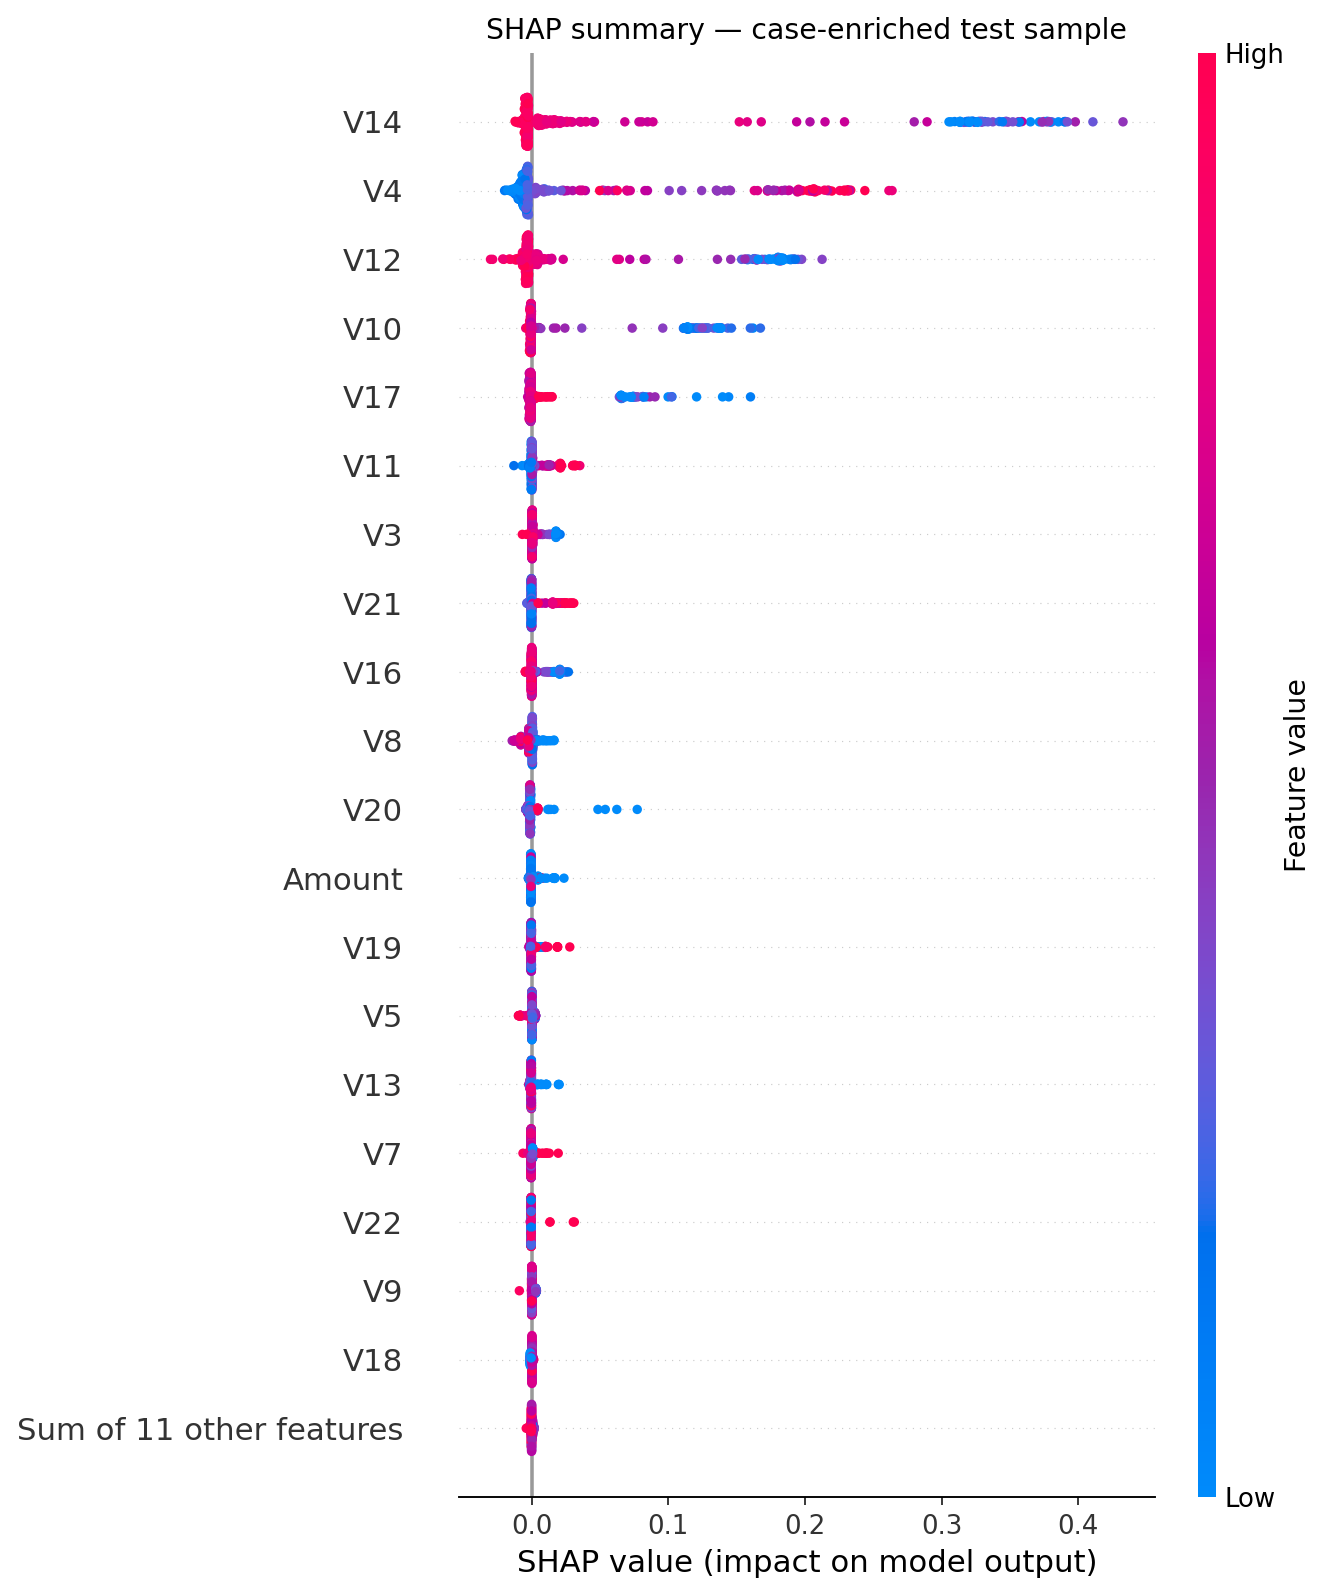

In [3]:
display(Image(filename=str(REPORTS / "global_shap_beeswarm.png")))

## 3. Local explanation: one transaction

A waterfall plot starts from the background baseline and adds/subtracts feature contributions until it reaches the model output for one row. We saved three examples under the Phase 6 cost-based threshold:

- **True positive:** actual fraud and flagged.
- **False positive:** legitimate transaction but flagged.
- **False negative:** actual fraud that was not flagged.

These are selected examples, not a random prevalence-representative sample.

In [4]:
local = json.loads((REPORTS / "local_explanations.json").read_text(encoding="utf-8"))
for case_name, case in local.items():
    top = case["top_features_by_absolute_contribution"][:5]
    print(f"\n{case_name}: actual={case['actual_class']}, score={case['model_score']:.6f}, "
          f"risk={case['risk_level']}, decision={case['decision']}")
    print("Top feature contributions:", [(x["feature"], round(x["shap_value"], 5)) for x in top])


true_positive: actual=1, score=0.986611, risk=CRITICAL, decision=FLAG_FOR_REVIEW
Top feature contributions: [('V14', 0.3096), ('V4', 0.20198), ('V12', 0.16582), ('V10', 0.11161), ('V17', 0.06414)]

false_positive: actual=0, score=0.975892, risk=CRITICAL, decision=FLAG_FOR_REVIEW
Top feature contributions: [('V14', 0.35618), ('V4', 0.1772), ('V12', 0.15827), ('V10', 0.13603), ('V17', 0.07755)]

false_negative: actual=1, score=0.778995, risk=HIGH, decision=NOT_FLAGGED
Top feature contributions: [('V14', 0.3771), ('V10', 0.16741), ('V17', 0.09026), ('V12', 0.07178), ('Amount', 0.02362)]


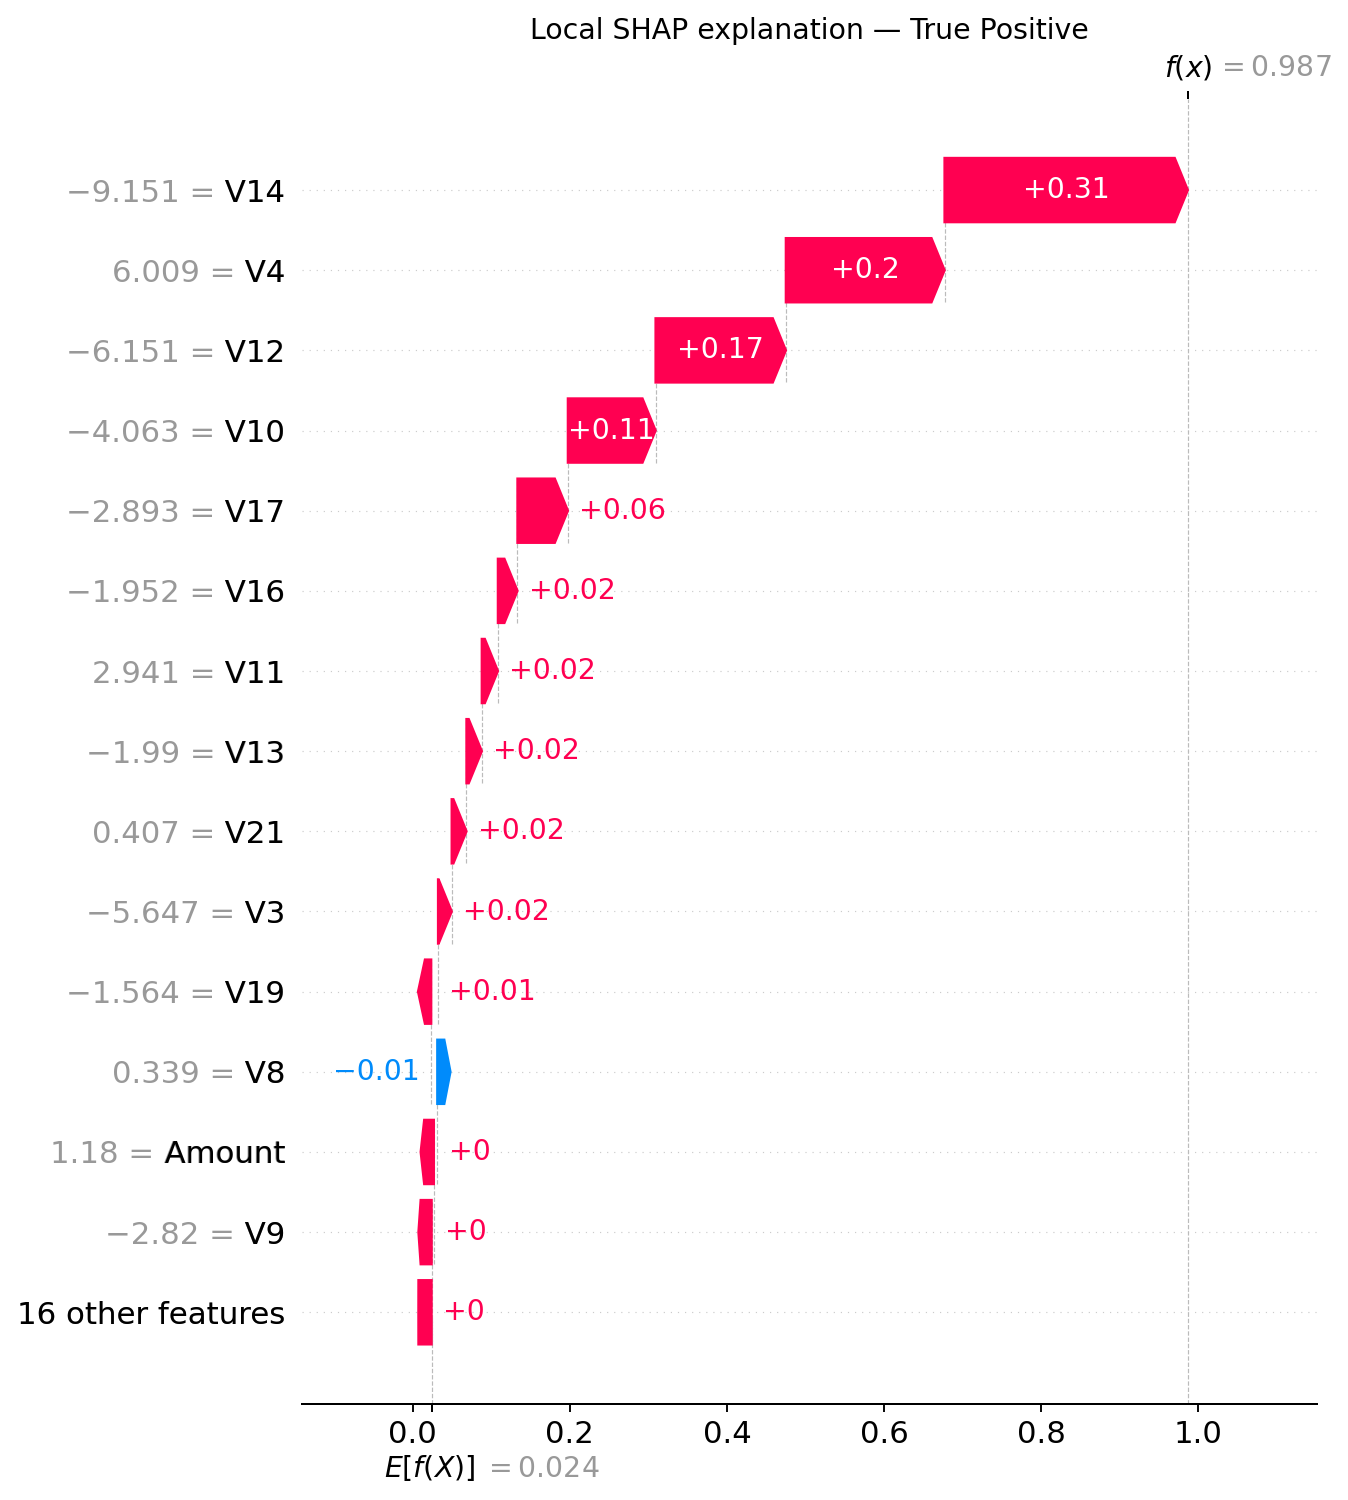

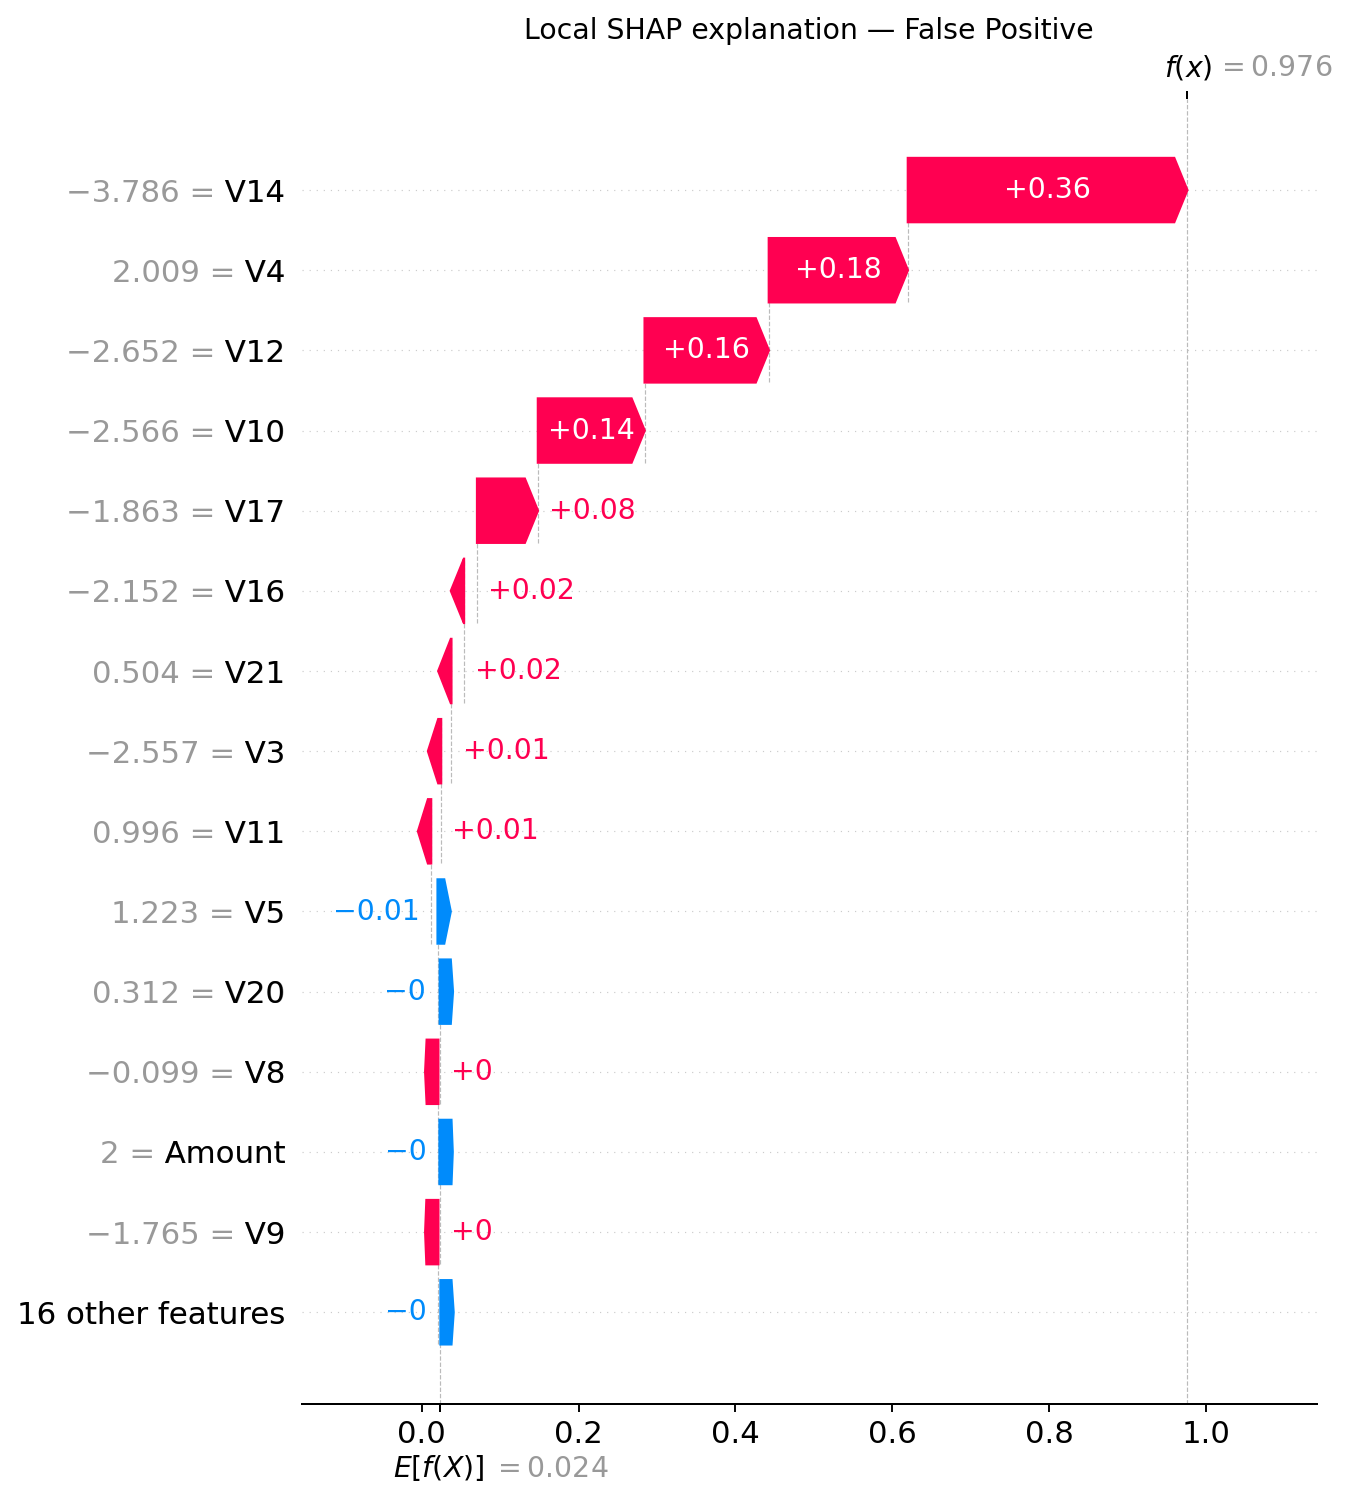

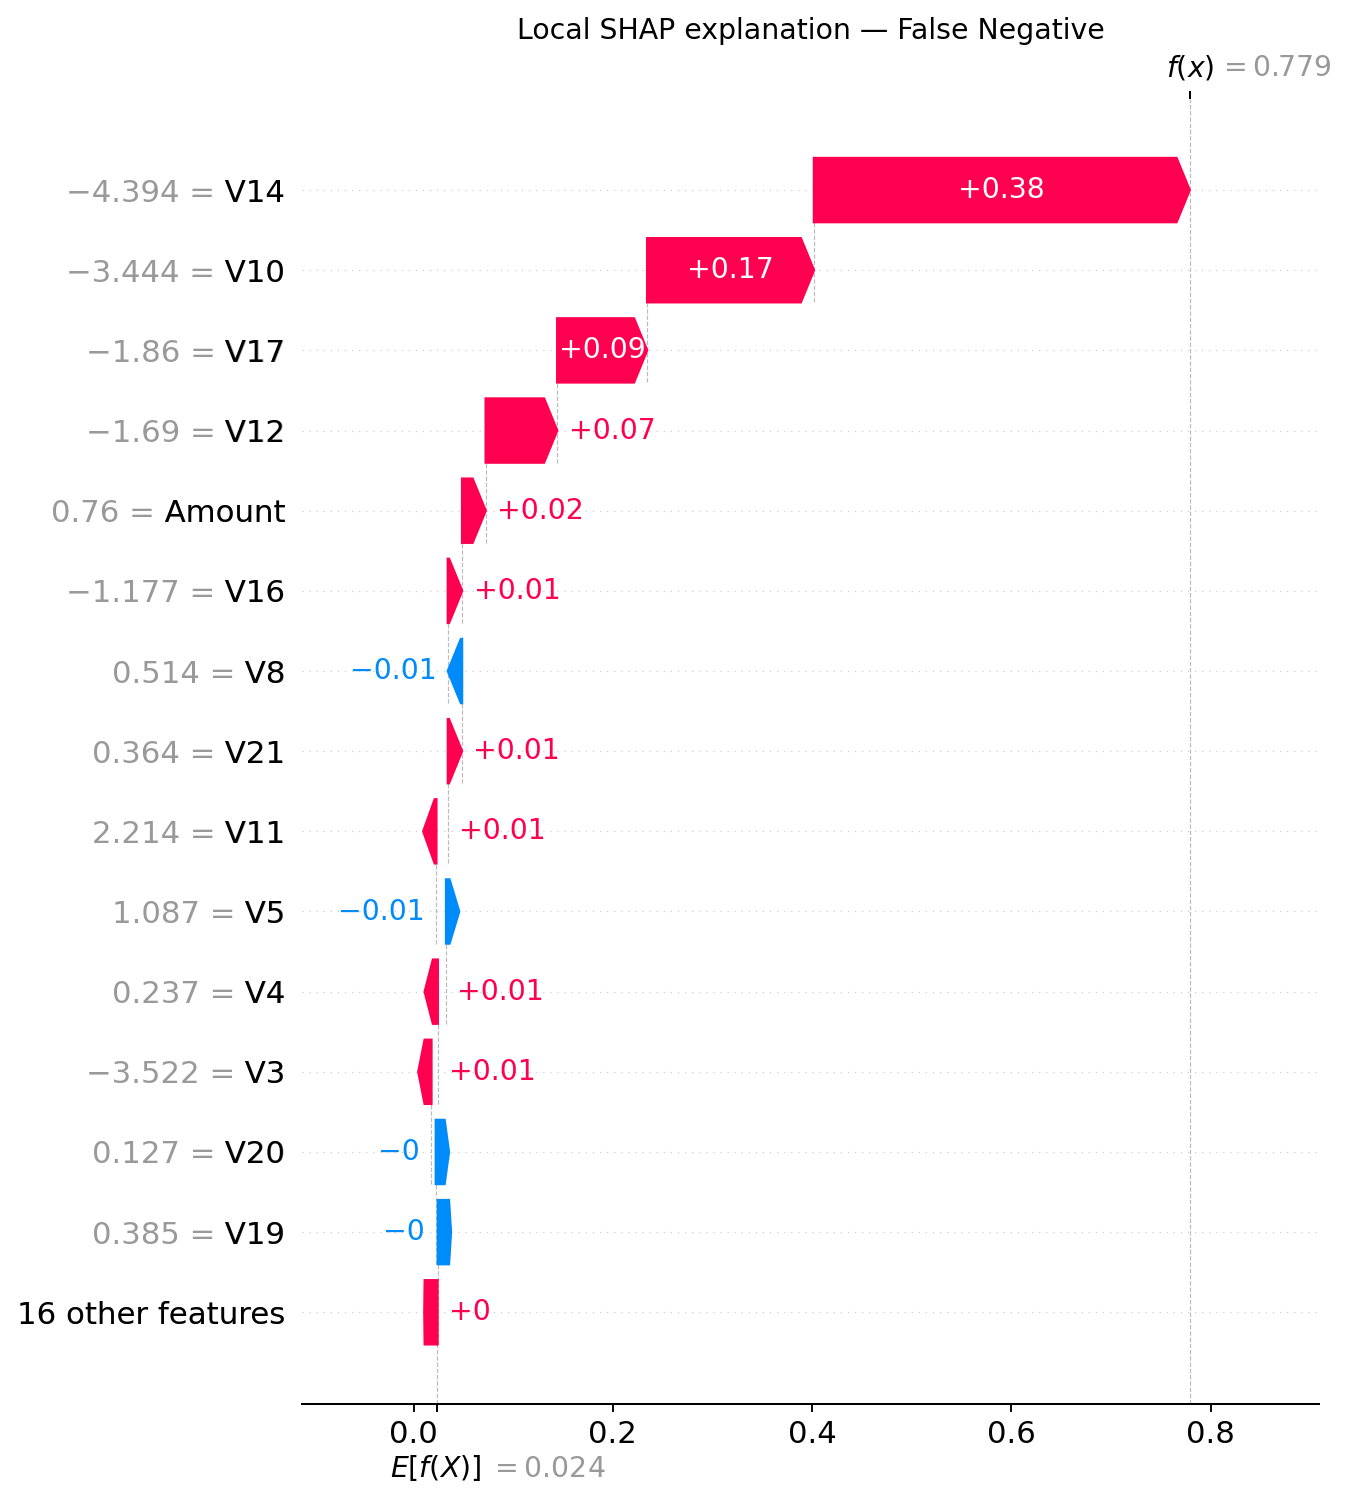

In [5]:
display(Image(filename=str(REPORTS / "local" / "waterfall_true_positive.png")))
display(Image(filename=str(REPORTS / "local" / "waterfall_false_positive.png")))
display(Image(filename=str(REPORTS / "local" / "waterfall_false_negative.png")))

## 4. Explanation API

The focused FastAPI endpoint accepts all 30 model features and returns the score, Phase 6 decision, top positive contributions, and top negative contributions. The example request is a public-dataset example from the test partition.

Start the service from the project root using:

```powershell
uvicorn api.main:app --reload
```

Then open `http://127.0.0.1:8000/docs` and call `POST /explain`. This demo API has no authentication; do not expose it to the public Internet until access controls, rate limits, and deployment security are implemented.

In [6]:
example = json.loads((REPORTS / "example_explain_request.json").read_text(encoding="utf-8"))
print("Request feature count:", len(example))
# Optional live API smoke test. This initializes the SHAP explainer in-process.
from fastapi.testclient import TestClient
from api.main import app, get_explanation_service
get_explanation_service.cache_clear()
with TestClient(app) as client:
    response = client.post("/explain?top_k=5", json=example)
print("HTTP status:", response.status_code)
api_result = response.json()
print("Score:", round(api_result["model_score"], 6))
print("Decision:", api_result["decision"], "| Risk level:", api_result["risk_level"])
print("Max SHAP additivity error:", api_result["shap_additivity_error"])
print("Top positive drivers:", [(x["feature"], round(x["shap_value"], 5)) for x in api_result["top_positive_contributions"]])

Request feature count: 30


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HTTP status: 200
Score: 0.986611
Decision: FLAG_FOR_REVIEW | Risk level: CRITICAL
Max SHAP additivity error: -7.810649449435658e-08
Top positive drivers: [('V14', 0.3096), ('V4', 0.20198), ('V12', 0.16582), ('V10', 0.11161), ('V17', 0.06414)]


## 5. Reproduce the artifacts

The following command rebuilds the background sample, global importance and beeswarm charts, local waterfall plots, explanation JSON/CSVs, and report. It does not retrain XGBoost or tune the Phase 6 threshold.

```powershell
python -m src.evaluation.shap_explanations
python -m pytest -q
```

The saved global summary is case-enriched by design. If you need a population-level estimate of overall feature contribution, run a separate representative sample and report it distinctly from a fraud-enriched analysis.